## Initial Setup

In [1]:
# https://medium.datadriveninvestor.com/automating-technical-analysis-pattern-recognition-bcbc85e4ec3c
## Run This Cell for Colab
!pip install yahoo_fin
!pip install mplfinance
!pip install pycaret
!pip install ta-lib
!pip install pytictoc
!pip install matplotlib
!pip install ipympl
!pip install jupyter-matplotlib

ERROR: Could not find a version that satisfies the requirement jupyter-matplotlib (from versions: none)
ERROR: No matching distribution found for jupyter-matplotlib


In [2]:
#Importing Libraries
import pandas as pd
import datetime
from datetime import date
from datetime import timedelta
import matplotlib.pyplot as plt
import yahoo_fin.stock_info as si
from yahoo_fin.stock_info import get_quote_table
from yahoo_fin.stock_info import get_stats
from yahoo_fin.stock_info import get_live_price
from pytictoc import TicToc
import talib
import numpy as np
import mplfinance as mpf
from talib import abstract
t=TicToc()
import warnings
warnings.filterwarnings('ignore')

### Functions

In [3]:
##Getting Patterns

def convert_to_plain_number(value_str):
    if not isinstance(value_str, str):
        return value_str
    
    value_str = value_str.replace(',', '')  # Remove any commas in the value (e.g., for numbers with thousands separators)
    multiplier = 1

    if value_str[-1] == 'B':
        multiplier = 1e9  # 1 billion = 1,000,000,000
    elif value_str[-1] == 'M':
        multiplier = 1e6  # 1 million = 1,000,000
    elif value_str[-1] == 'K':
        multiplier = 1e3  # 1 thousand = 1,000
    elif value_str[-1] == 'T':
        multiplier = 1e12  # 1 trillion = 1,000,000,000,000

    return float(value_str[:-1]) * multiplier

def get_patterns(data=None,ticker_column = 'ticker',mute=False):
    #from talib import abstract
    result = pd.DataFrame()
    tickers = data[ticker_column].unique()
    x=[]
    attr = talib.get_function_groups()['Pattern Recognition']
    for i in tickers:
        df = data[data[ticker_column]==i]
        for a in attr:
            df[a] = (getattr(abstract,a)(df))/100
        result = pd.concat([result,df])
        x.append(i)
        if mute is False:
            print(i + " Patterns Appended Successfully")
            print(result.shape)
            print(str(len(x)) + " of "+ str(len(tickers)) + " Done ")
        else:
            pass
    return result

#Creating Indicators

def get_indicators(data=None,ticker_column = 'ticker',price_column="close",mute=False):
    result = pd.DataFrame()
    tickers = data[ticker_column].unique()
    x=[]
    for i in tickers:
        df = data[data[ticker_column]==i]
        df["Vol_over_30DAvg"] = df["volume"]/df["volume"].rolling(window=30).mean()
        df["Vol_over_10DAvg"] = df["volume"]/df["volume"].rolling(window=10).mean()
        df["Perc_From_200D_H"] = ((df[price_column]/df[price_column].rolling(window=200).max())-1)*100
        df["Perc_From_200D_L"] = ((df[price_column]/df[price_column].rolling(window=200).min())-1)*100
        df["Retracement_200D"] = df[price_column]/(df[price_column].rolling(window=200).max()-df[price_column].rolling(window=30).min())
        df["Perc_From_30D_H"] = ((df[price_column]/df[price_column].rolling(window=30).max())-1)*100
        df["Perc_From_30D_L"] = ((df[price_column]/df[price_column].rolling(window=30).min())-1)*100
        df["Retracement_30D"] = df[price_column]/(df[price_column].rolling(window=30).max()-df[price_column].rolling(window=30).min())
        df["30D/200D_High"] = df[price_column].rolling(window=30).max()/df[price_column].rolling(window=200).max()
        df["30D/200D_Low"] = df[price_column].rolling(window=30).min()/df[price_column].rolling(window=200).min()
        df["Perc_from 60DEMAVG"] = ((df[price_column]/df[price_column].rolling(window=60).mean())-1)*100
        df["Perc_from 30DEMAVG"] = ((df[price_column]/df[price_column].rolling(window=30).mean())-1)*100
        df["Perc_from 200DEMAVG"] = ((df[price_column]/df[price_column].rolling(window=200).mean())-1)*100
        df["Variand_30D/200D"] = df[price_column].rolling(window=30).var()/df[price_column].rolling(window=200).var()
        df = df.dropna()
        df = df.sort_index(ascending=True)
        result = pd.concat([result,df])
        
        if mute is False:
            print(i + " Indicators Appended Successfully")
            print(result.shape)
            x.append(i)
            print(str(len(x)) + " of "+ str(len(tickers)) + " Done ")
        else:
            pass

    return result

## Getting Labels

def get_labels(data = None,ticker_column="ticker", fwd_window=1,price_column="close",threshold_perc=1,mute=False):
    result = pd.DataFrame()
    tickers = data[ticker_column].unique()
    x=[]
    for i in tickers:
        df = data[data[ticker_column]==i]
        df.sort_index(ascending=False)
        df["Change"] = df[price_column].pct_change(periods=fwd_window).shift(-fwd_window)
        df["Change"]=np.where(abs(df["Change"])>=(threshold_perc/100),df["Change"]/abs(df["Change"]),0)
        result= pd.concat([result,df],axis=0)
        if mute is False:    
            print(i + " Labels Appended Successfully")
            print(result.shape)
            x.append(i)
            print(str(len(x)) + " of "+ str(len(tickers)) + " Done ")
        else:
            pass
    result.dropna(inplace=True)
    return result


## Compile Data

def compile_data(data=None,ticker_column = 'ticker',price_column="close",fwd_window=1,threshold_perc=1,mute=False,train=True):
    print("Compiling pattern Signals")
    data_patterns = get_patterns(data=data,ticker_column=ticker_column,mute=mute)
    print ("---- Pattern Signals Attached")
    print("Compiling Indicators")
    data_indicators = get_indicators(data=data_patterns,ticker_column=ticker_column,price_column=price_column,mute=mute)
    print ("---- Indicators Attached")
    print ("Creating Labels")
    data_labelled = get_labels(data=data_indicators,ticker_column=ticker_column,price_column="close", fwd_window=fwd_window,threshold_perc=1,mute=mute)
    print("---- All Labels Attached")
    if train is True:
        return data_labelled
    else:
        return data_indicators

#Getting Pattern based signals

def get_pattern_signals(tickers=None,top=5):
    d=pd.DataFrame()
    start_date = date.today() - timedelta(days=200)
    start_date= start_date.strftime('%m/%d/%Y')
    end_date = date.today().strftime('%m/%d/%Y')
    for i in tickers:
        
        a = si.get_data(ticker = i, start_date=start_date,end_date=end_date)
        z = get_patterns(data=a,mute=True).iloc[-1,6:]
        
        d= pd.concat((d,z),axis=1)
        print(i + "   ",end="\r")
    d.columns = d.iloc[0]
    d=d.drop("ticker")
    d=d.sum()/d.count()
    d=d.sort_values(ascending=False)
    top_buy = d[d>0].head(top).sort_values(ascending=False)
    top_sell = d[d<0].tail(top).sort_values(ascending=True)
    print("Top Buy Ideas")
    print(top_buy)
    print("Top Sell Ideas")
    print(top_sell)
    return top_buy,top_sell

## Getting Top MCap Tickers

def get_top_tickers (index_name = 'sp500',top=50, tickers = None):
    ''' For index_name, you can choose from the following:\n
        'sp500'   - S&P 500 Index \n
        'dow'     - Dow Jones Industrial Average \n
        'nasdaq'  - Companies listed on Nasdaq\n
        'nifty50' - For NIFTY50\n
        'ftse100' - For FTSE100\n
        'ftse250' - For FTSE250\n
        Or for any other index not listed above, a list of all the tickers can be passed to filter out Top N companies by Market Capitalization '''
    mcap=[]
    if tickers is None:
        t = "tickers_"+index_name
        # tickers = getattr(si,t)()
        # get only for sp500 top 20
        tickers = si.tickers_sp500()
        tickers = tickers[:20]
    else:
        pass

    print("Processing tickers")
    for i in tickers:
        #a= si.get_quote_data(i)
        print("Processing " + i)
        a = get_stats(i)
        a_df = pd.DataFrame(a)
        if str(a_df.iloc[9, 1]) == 'nan' or str(a_df.iloc[9, 1]) == "NaN":
            continue
        b=round(convert_to_plain_number(a_df.iloc[9, 1])*get_live_price(i)/1000000)
        mcap.append(b)
    mcap_df = pd.DataFrame()
    mcap_df["Tickers"] = tickers
    mcap_df["MCap_mn"] = mcap
    mcap_df=mcap_df.sort_values(by=["MCap_mn"],ascending=False)
    top_mcap_tickers = mcap_df.head(top)["Tickers"]
    return top_mcap_tickers.to_list()

## Getting Historical Bulk Data for Download

def get_hist_data (tickers=None,time_window =1000,start_date=None,delta =1):
    i_list=[]
    data = pd.DataFrame()
    if start_date is None:
        start_date = date.today() - timedelta(days= time_window)
        start_date= start_date.strftime('%m/%d/%Y')
    else:
        start_date= start_date.strftime('%m/%d/%Y')
    end_date = date.today() - timedelta(days=delta)
    end_date= end_date.strftime('%m/%d/%Y')
    for i in tickers:
        a = si.get_data(ticker = i, start_date=start_date,end_date=end_date)
        data = pd.concat([data,a],axis=0)
        print(i+" Appended Successfully")
        print(data.shape)
        i_list.append(i)
        print(str(len(i_list)) + " of "+ str(len(tickers)) + " Done ")
        data.drop_duplicates(inplace = True)
        data.dropna(inplace=True)
    return data

In [4]:
import ssl
ssl._create_default_https_context = ssl._create_unverified_context

sp500_tickers = si.tickers_sp500()
print(sp500_tickers[:20])

['A', 'AAL', 'AAP', 'AAPL', 'ABBV', 'ABC', 'ABT', 'ACGL', 'ACN', 'ADBE', 'ADI', 'ADM', 'ADP', 'ADSK', 'AEE', 'AEP', 'AES', 'AFL', 'AIG', 'AIZ']


#### Selecting Top MCap Companies

In [5]:
import ssl
ssl._create_default_https_context = ssl._create_unverified_context

top_100 = get_top_tickers(index_name='sp500',top=100)
top_100

Processing tickers
Processing A
Processing AAL
Processing AAP
Processing AAPL
Processing ABBV
Processing ABC
Processing ABT
Processing ACGL
Processing ACN
Processing ADBE
Processing ADI
Processing ADM
Processing ADP
Processing ADSK
Processing AEE
Processing AEP
Processing AES
Processing AFL
Processing AIG
Processing AIZ


['AAPL',
 'ABBV',
 'ADBE',
 'ACN',
 'ABT',
 'ADP',
 'ADI',
 'ADM',
 'ADSK',
 'AEP',
 'AFL',
 'AIG',
 'ABC',
 'A',
 'ACGL',
 'AEE',
 'AES',
 'AAL',
 'AIZ',
 'AAP']

In [6]:
top_100[:10]
print(top_100)

['AAPL', 'ABBV', 'ADBE', 'ACN', 'ABT', 'ADP', 'ADI', 'ADM', 'ADSK', 'AEP', 'AFL', 'AIG', 'ABC', 'A', 'ACGL', 'AEE', 'AES', 'AAL', 'AIZ', 'AAP']


## Simple Pattern Based Signal Generation

In [7]:
patterns = talib.get_function_groups()['Pattern Recognition']
print("No. of patterns - "+ str(len(patterns)))
print(patterns[0:5])

No. of patterns - 61
['CDL2CROWS', 'CDL3BLACKCROWS', 'CDL3INSIDE', 'CDL3LINESTRIKE', 'CDL3OUTSIDE']


In [8]:
aapl = get_hist_data(tickers=["aapl"],time_window=1000)
aapl.tail()

aapl Appended Successfully
(687, 7)
1 of 1 Done 


,open,high,low,close,adjclose,volume,ticker
2023-07-21,194.100006,194.970001,191.229996,191.940002,191.940002,71917800,AAPL
2023-07-24,193.410004,194.910004,192.250000,192.750000,192.750000,45377800,AAPL
2023-07-25,193.330002,194.440002,192.919998,193.619995,193.619995,37283200,AAPL
2023-07-26,193.669998,195.639999,193.320007,194.500000,194.500000,47471900,AAPL
2023-07-27,196.020004,197.199997,192.550003,193.220001,193.220001,47460200,AAPL


In [9]:
aapl_patterns = get_patterns(data=aapl)
aapl_patterns.iloc[:,-4:].tail()

AAPL Patterns Appended Successfully
(687, 68)
1 of 1 Done 


,CDLTRISTAR,CDLUNIQUE3RIVER,CDLUPSIDEGAP2CROWS,CDLXSIDEGAP3METHODS
2023-07-21,0.0,0.0,0.0,0.0
2023-07-24,0.0,0.0,0.0,0.0
2023-07-25,0.0,0.0,0.0,0.0
2023-07-26,0.0,0.0,0.0,0.0
2023-07-27,0.0,0.0,0.0,0.0


In [10]:
aapl_patterns.iloc[:,:5].head()

,open,high,low,close,adjclose
2020-11-02,109.110001,110.680000,107.320000,108.769997,106.983116
2020-11-03,109.660004,111.489998,108.730003,110.440002,108.625679
2020-11-04,114.139999,115.589996,112.349998,114.949997,113.061584
2020-11-05,117.949997,119.620003,116.870003,119.029999,117.074562
2020-11-06,118.320000,119.199997,116.129997,118.690002,116.941559


In [11]:
aapl_patterns["sum_flags"] = aapl_patterns[patterns].sum(axis=1)
print("Total Observation - " + str(aapl_patterns.shape[0]))
print("Observations with Flag - " + str(aapl_patterns[aapl_patterns["sum_flags"]!=0].shape[0]) )

Total Observation - 687
Observations with Flag - 507


In [12]:
print(patterns)

['CDL2CROWS', 'CDL3BLACKCROWS', 'CDL3INSIDE', 'CDL3LINESTRIKE', 'CDL3OUTSIDE', 'CDL3STARSINSOUTH', 'CDL3WHITESOLDIERS', 'CDLABANDONEDBABY', 'CDLADVANCEBLOCK', 'CDLBELTHOLD', 'CDLBREAKAWAY', 'CDLCLOSINGMARUBOZU', 'CDLCONCEALBABYSWALL', 'CDLCOUNTERATTACK', 'CDLDARKCLOUDCOVER', 'CDLDOJI', 'CDLDOJISTAR', 'CDLDRAGONFLYDOJI', 'CDLENGULFING', 'CDLEVENINGDOJISTAR', 'CDLEVENINGSTAR', 'CDLGAPSIDESIDEWHITE', 'CDLGRAVESTONEDOJI', 'CDLHAMMER', 'CDLHANGINGMAN', 'CDLHARAMI', 'CDLHARAMICROSS', 'CDLHIGHWAVE', 'CDLHIKKAKE', 'CDLHIKKAKEMOD', 'CDLHOMINGPIGEON', 'CDLIDENTICAL3CROWS', 'CDLINNECK', 'CDLINVERTEDHAMMER', 'CDLKICKING', 'CDLKICKINGBYLENGTH', 'CDLLADDERBOTTOM', 'CDLLONGLEGGEDDOJI', 'CDLLONGLINE', 'CDLMARUBOZU', 'CDLMATCHINGLOW', 'CDLMATHOLD', 'CDLMORNINGDOJISTAR', 'CDLMORNINGSTAR', 'CDLONNECK', 'CDLPIERCING', 'CDLRICKSHAWMAN', 'CDLRISEFALL3METHODS', 'CDLSEPARATINGLINES', 'CDLSHOOTINGSTAR', 'CDLSHORTLINE', 'CDLSPINNINGTOP', 'CDLSTALLEDPATTERN', 'CDLSTICKSANDWICH', 'CDLTAKURI', 'CDLTASUKIGAP', 'CDL

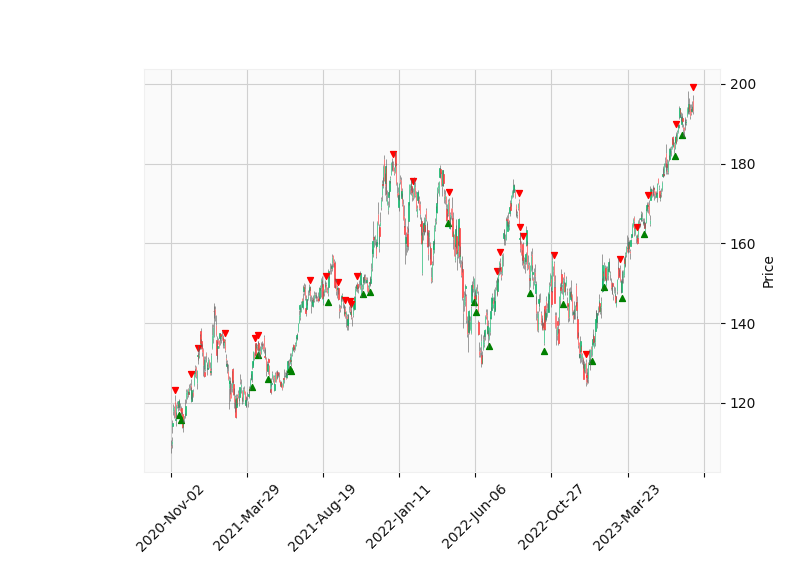

In [13]:
# Visualizing a pattern on candle stick chart

aapl_engulfing = aapl_patterns['CDLENGULFING']
aapl_engulfing_bullish = (aapl_engulfing.replace([-1,0],np.nan))*aapl_patterns.low*0.99
aapl_engulfing_bearish = (-aapl_engulfing.replace([1,0],np.nan))*aapl_patterns.high*1.01
%matplotlib ipympl
addplot = [mpf.make_addplot(aapl_engulfing_bullish,type='scatter',color = 'g',marker = '^'), 
            mpf.make_addplot(aapl_engulfing_bearish,type='scatter',color = 'r',marker = 'v')]
mpf.plot(aapl_patterns.iloc[:,:5],addplot=addplot,type='candle',style= 'yahoo')

In [14]:
top_100[:10]

['AAPL', 'ABBV', 'ADBE', 'ACN', 'ABT', 'ADP', 'ADI', 'ADM', 'ADSK', 'AEP']

In [15]:
# Pattern based signal generation
top_buy,top_sell=get_pattern_signals(tickers=top_100,top=5)

Top Buy Ideas
ticker
AAL    0.098361
ADM    0.098361
ADI    0.081967
AFL    0.065574
AES    0.065574
dtype: object
Top Sell Ideas
ticker
ABC    -0.032787
ACGL   -0.032787
AEE    -0.016393
AIZ    -0.016393
dtype: object
